## Read the data from the .mat file 

The data comes from here: https://zenodo.org/records/5957394

In [1]:
import h5py

# Get the available variables in the .mat file
df = h5py.File(r"C:\Users\natal\Downloads\NREL_Trainset40000.mat", "r")
print(list(df.keys()))

['Fzz', 'Hs', 'Mxx', 'Myy', 'Pitch_mean', 'Pitch_std', 'Rpm_mean', 'Rpm_std', 'Tp', 'Vw_mean', 'Vw_std', 'Wave_dir', 'Wdir_mean', 'Wdir_std', 'Yaw_mean', 'Yaw_std', 'skip']


In [2]:
for key in df.keys():
    print(key, df[key].shape, df[key].dtype)

Fzz (1194930000, 1) float64
Hs (39831, 1) float64
Mxx (1194930000, 1) float64
Myy (1194930000, 1) float64
Pitch_mean (39831, 1) float64
Pitch_std (39831, 1) float64
Rpm_mean (39831, 1) float64
Rpm_std (39831, 1) float64
Tp (39831, 1) float64
Vw_mean (39831, 1) float64
Vw_std (39831, 1) float64
Wave_dir (39831, 1) int16
Wdir_mean (39831, 1) float64
Wdir_std (39831, 1) float64
Yaw_mean (39831, 1) float64
Yaw_std (39831, 1) float64
skip (169, 1) int64


In [3]:
len(df["Vw_mean"])

39831

In [21]:
# Get the data for a specific variable
U = df["Vw_mean"][:]            # Mean wind speed (m/s)
Hs = df["Hs"][:]                # Significant wave height (m)
Tp = df["Tp"][:]                # Peak wave period (s)
U_dir = df["Wdir_mean"][:]      # Wind direction (degrees)

Fzz = df["Fzz"][:]              # Reaction force at the mudline (N)
Mxx = df["Mxx"][:]              # Reaction moment at the mudline (N*m)
Myy = df["Myy"][:]              # Reaction moment at the mudline (N*m)

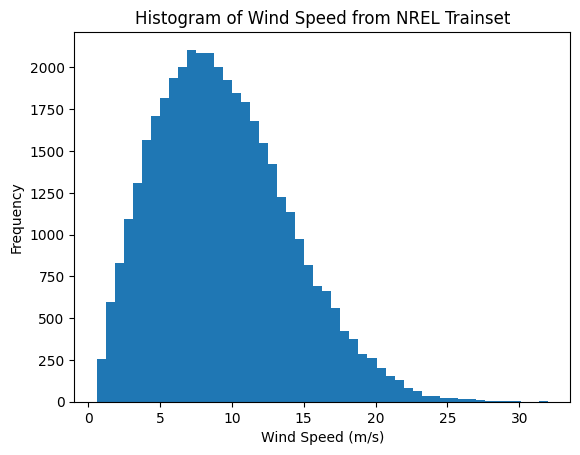

In [18]:
import matplotlib.pyplot as plt

plt.hist(U.flatten(), bins=50)
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Frequency")
plt.title("Histogram of Wind Speed from NREL Trainset")
plt.show()

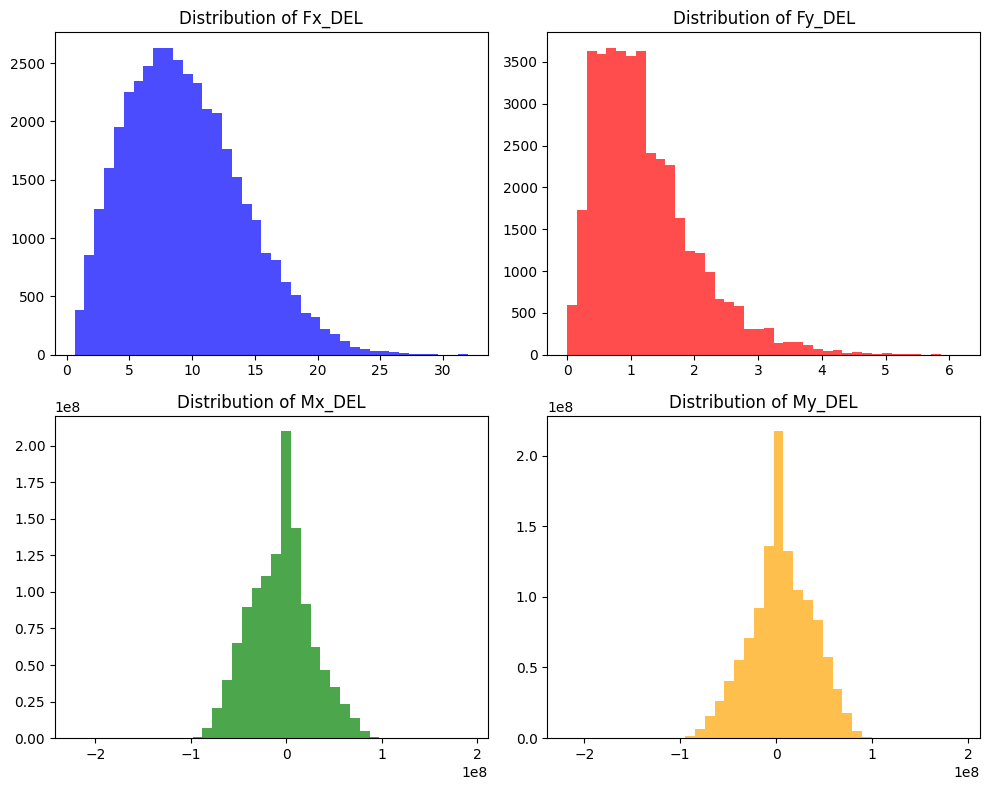

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

axes[0].hist(U.flatten(), bins=40, color="blue", alpha=0.7)
axes[1].hist(Hs.flatten(), bins=40, color="red", alpha=0.7)
axes[2].hist(Mxx.flatten(), bins=40, color="green", alpha=0.7)
axes[3].hist(Myy.flatten(), bins=40, color="orange", alpha=0.7)

axes[0].set_title("Distribution of Fx_DEL")
axes[1].set_title("Distribution of Fy_DEL")
axes[2].set_title("Distribution of Mx_DEL")
axes[3].set_title("Distribution of My_DEL")

plt.tight_layout()
plt.show()